# 421 – A Quantum GAN that Learns a Log-normal Distribution

**Goal.** Train a quantum circuit so that measuring it produces samples distributed like a
given dataset – here, 1000 samples from a **log-normal** distribution.

**Why bother?** Many quantum algorithms (e.g. amplitude estimation for finance, `424`) need a
probability distribution **loaded into a quantum state**:
$\;|g_\theta\rangle = \sum_j \sqrt{p_\theta(j)}\,|j\rangle$.
Preparing an arbitrary state exactly needs very deep circuits.  A qGAN learns a *shallow*
circuit that prepares a good approximation instead
([Zoufal, Lucchi, Woerner, npj Quantum Information 5, 103 (2019)](https://arxiv.org/abs/1904.00043)).

**The two players**

* **Quantum generator** $G_\theta$ – a parameterised circuit on $n$ qubits.  Each of the $2^n$
  basis states $|j\rangle$ stands for one grid point $x_j$; measuring gives $x_j$ with
  probability $p_\theta(j)$.
* **Classical discriminator** $D_\phi$ – a small neural network that outputs the probability
  $D_\phi(x)\in[0,1]$ that $x$ is *real*.

**Modern tooling.** The generator is a `SamplerQNN` (the network type from `411`) wrapped in a
`TorchConnector`, so **PyTorch** can train it next to the discriminator.  This replaces the
`QGAN` class of the retired Qiskit Aqua.  Here every step is written out; later notebooks reuse
the same code from `qml_qgan.py`.


| Notebook | Topic |
|---|---|
| `420` | the generator / discriminator idea, with plain circuits (no training) |
| `421` | **a full qGAN**: learn a 1-D log-normal distribution |
| `422` | 2-D data with correlations – why entanglement matters |
| `423` | a real dataset (used-car prices) |
| `424` | application: price a financial option with a trained generator + amplitude estimation |
| `425` | experiments: what makes qGAN training stable? |

**Prerequisites:** `420`, `411` (`SamplerQNN`), `303` (sampling distributions) – and a little
PyTorch (tensors, `nn.Module`, optimisers).

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.stats import entropy

from qiskit import QuantumCircuit
from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.gradients import ParamShiftSamplerGradient
from qiskit_machine_learning.neural_networks import SamplerQNN

torch.manual_seed(42)

## Step 1 – Training data and the grid

The generator can only output $2^n$ different values, so we lay a **grid** over the data range.
With $n = 3$ qubits and bounds $[0, 7]$ the grid is $\{0, 1, \dots, 7\}$.  Every sample is
snapped to the nearest grid point (samples above 7 are dropped), which turns the data into a
target distribution `prob_data` over the 8 grid points.

852 of 1000 samples lie inside the bounds
target distribution: [0.047 0.275 0.224 0.183 0.107 0.079 0.056 0.029]


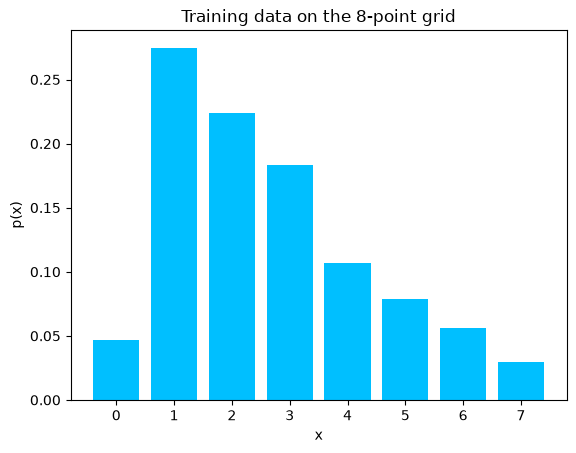

In [3]:
rng = np.random.default_rng(71)
real_data = rng.lognormal(mean=1, sigma=1, size=1000)

bounds = np.array([0., 7.])
num_qubits = 3
grid = np.linspace(bounds[0], bounds[1], 2 ** num_qubits)   # 0, 1, ..., 7

inside = real_data[real_data <= bounds[1]]
snapped = np.abs(inside[:, None] - grid[None, :]).argmin(axis=1)
prob_data = np.bincount(snapped, minlength=len(grid)) / len(inside)

print(f"{len(inside)} of {len(real_data)} samples lie inside the bounds")
print("target distribution:", prob_data.round(3))

plt.bar(grid, prob_data, color='deepskyblue')
plt.title('Training data on the 8-point grid')
plt.xlabel('x'); plt.ylabel('p(x)')
plt.show()

## Step 2 – The quantum generator

* **Hadamards** on all qubits start the generator in the *uniform* distribution.
* **`efficient_su2`** (one repetition) adds trainable $R_Y$ / $R_Z$ rotations and a layer of
  CNOTs – 12 parameters in total.

`SamplerQNN` with `input_params=[]` has **no inputs**: its output is simply the vector of the 8
probabilities $p_\theta(j)$.  Gradients come from the *parameter-shift rule*.  2000 shots per
evaluation keep training quick at ~1 % statistical error.

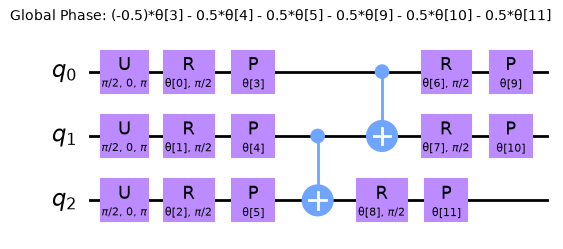

In [4]:
qc = QuantumCircuit(num_qubits)
qc.h(range(num_qubits))
qc.compose(efficient_su2(num_qubits, reps=1), inplace=True)
qc.decompose().draw(output='mpl', style='clifford')

In [5]:
sampler = StatevectorSampler(default_shots=2000, seed=42)
generator_qnn = SamplerQNN(circuit=qc, sampler=sampler, input_params=[],
                           weight_params=qc.parameters, sparse=False,
                           gradient=ParamShiftSamplerGradient(sampler))

initial_weights = np.random.default_rng(1).random(qc.num_parameters)
generator = TorchConnector(generator_qnn, initial_weights=initial_weights)

with torch.no_grad():
    p_start = generator(torch.tensor([])).numpy()
print("trainable weights:", qc.num_parameters)
print("initial generator distribution:", p_start.round(3))

trainable weights: 12
initial generator distribution: [0.054 0.156 0.034 0.07  0.047 0.325 0.096 0.217]


## Step 3 – The classical discriminator

A tiny network: 1 input (the grid value, scaled to $[0,1]$) → 20 hidden units with leaky ReLU
→ 1 output with a sigmoid, read as "probability that this value is real".

In [6]:
class Discriminator(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_size, 20), nn.LeakyReLU(0.2),
                                 nn.Linear(20, 1), nn.Sigmoid())

    def forward(self, x):
        return self.net(x)

discriminator = Discriminator(1)

## Step 4 – The adversarial losses

Because the generator gives us the **exact list of probabilities** $p_\theta(j)$, we do not
need to draw samples: every grid point $x_j$ enters the losses *weighted* by its probability.

* **Discriminator** – binary cross entropy, real data labelled 1 and generated data labelled 0:
  $$L_D = -\tfrac12\sum_j \Big[p_{data}(j)\log D(x_j) + p_\theta(j)\log\big(1-D(x_j)\big)\Big]$$
* **Generator** – it wants its points to be called *real*:
  $$L_G = -\sum_j p_\theta(j)\,\log D(x_j)$$

The generator lowers $L_G$ by moving probability towards the points the discriminator
currently believes are real.

In [7]:
def adversarial_loss(prediction, target, weight):
    prediction = prediction.clamp(1e-7, 1 - 1e-7)
    bce = target * torch.log(prediction) + (1 - target) * torch.log(1 - prediction)
    return -torch.sum(weight * bce)

samples = torch.tensor(grid / bounds[1], dtype=torch.float).reshape(-1, 1)   # scaled to [0, 1]
real_prob = torch.tensor(prob_data, dtype=torch.float).reshape(-1, 1)
valid = torch.ones(len(grid), 1)    # label "real"
fake = torch.zeros(len(grid), 1)    # label "generated"

## Step 5 – Training

Each **epoch**: one Adam step for the generator, then **three** Adam steps for the
discriminator (with a higher learning rate).  Keeping the discriminator close to its best
response gives the generator a reliable signal; with equal treatment the two networks tend to
circle around each other instead of converging – notebook `425` shows this.

We track the **relative entropy** (Kullback–Leibler divergence) between generated and real
distribution: 0 means identical.  150 epochs take about 4 minutes.

In [8]:
num_epochs = 150
d_steps = 3
opt_g = torch.optim.Adam(generator.parameters(), lr=0.02, betas=(0.7, 0.999))
opt_d = torch.optim.Adam(discriminator.parameters(), lr=0.05, betas=(0.7, 0.999))

g_losses, d_losses, rel_entr = [], [], []
start = time.time()
for epoch in range(num_epochs):
    gen_prob = generator(torch.tensor([])).reshape(-1, 1)

    # generator step: make the discriminator call generated points "real"
    opt_g.zero_grad()
    g_loss = adversarial_loss(discriminator(samples), valid, gen_prob)
    g_loss.backward(retain_graph=True)
    opt_g.step()

    # discriminator steps: real -> 1, generated -> 0
    for _ in range(d_steps):
        opt_d.zero_grad()
        d_loss = (adversarial_loss(discriminator(samples), valid, real_prob)
                  + adversarial_loss(discriminator(samples), fake, gen_prob.detach())) / 2
        d_loss.backward()
        opt_d.step()

    g_losses.append(g_loss.item())
    d_losses.append(d_loss.item())
    rel_entr.append(entropy(gen_prob.detach().numpy().ravel() + 1e-10, prob_data + 1e-10))
    if (epoch + 1) % 25 == 0:
        print(f"epoch {epoch + 1:4d}   relative entropy {rel_entr[-1]:.4f}")

print(f"training time: {(time.time() - start) / 60:.1f} min")

epoch   25   relative entropy 0.3560


epoch   50   relative entropy 0.3496


epoch   75   relative entropy 0.2877


epoch  100   relative entropy 0.0598


epoch  125   relative entropy 0.0305


epoch  150   relative entropy 0.0078
training time: 2.4 min


## Step 6 – Training progress and outcome

The losses settle as the two players reach a balance, and the relative entropy falls towards 0.

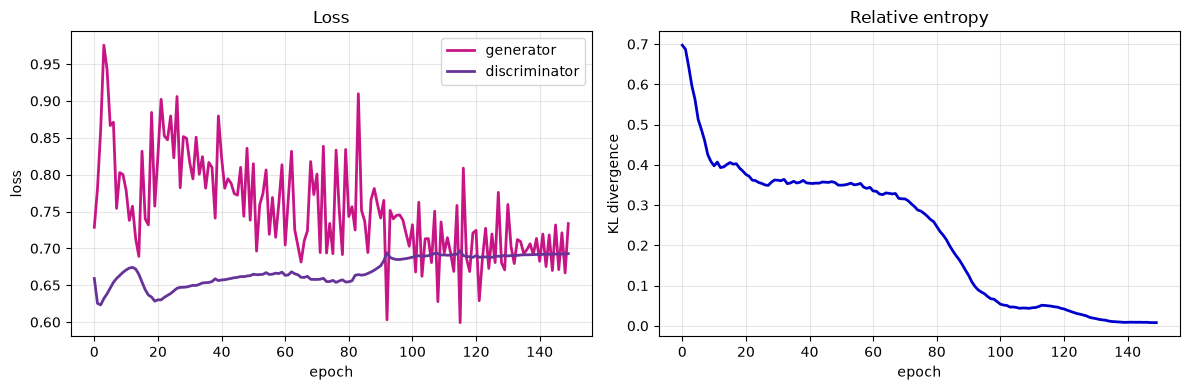

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(g_losses, label='generator', color='mediumvioletred', lw=2)
ax1.plot(d_losses, label='discriminator', color='rebeccapurple', lw=2)
ax1.set(title='Loss', xlabel='epoch', ylabel='loss'); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(rel_entr, color='mediumblue', lw=2)
ax2.set(title='Relative entropy', xlabel='epoch', ylabel='KL divergence'); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

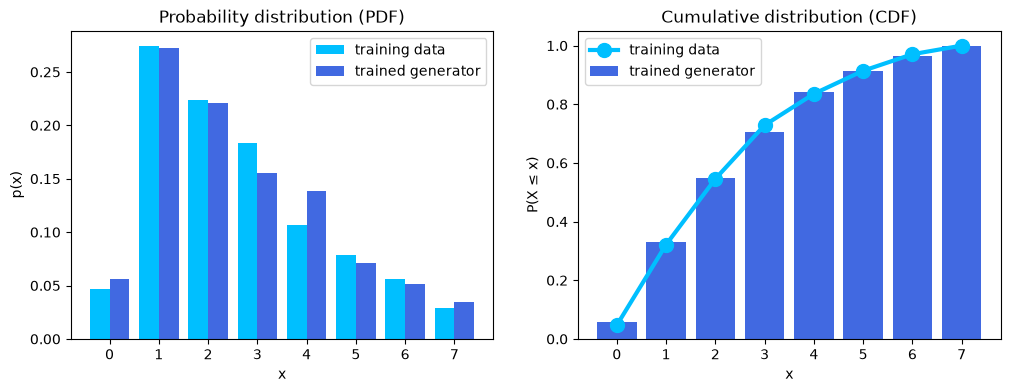

trained weights: [ 0.085  0.92   0.665  2.346  1.635  1.286  0.705 -0.55   0.196  0.028
  0.754  0.538]


In [10]:
with torch.no_grad():
    p_trained = generator(torch.tensor([])).numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(grid - 0.2, prob_data, width=0.4, label='training data', color='deepskyblue')
ax1.bar(grid + 0.2, p_trained, width=0.4, label='trained generator', color='royalblue')
ax1.set(title='Probability distribution (PDF)', xlabel='x', ylabel='p(x)'); ax1.legend()
ax2.bar(grid, np.cumsum(p_trained), color='royalblue', width=0.8, label='trained generator')
ax2.plot(grid, np.cumsum(prob_data), '-o', color='deepskyblue', lw=3, ms=10, label='training data')
ax2.set(title='Cumulative distribution (CDF)', xlabel='x', ylabel='P(X ≤ x)'); ax2.legend()
plt.show()
print("trained weights:", generator.weight.detach().numpy().round(3))

The trained circuit now **loads the log-normal distribution into a 3-qubit state**, and it is
only a few gates deep.  Notebook `424` uses exactly such a trained generator as the input of a
quantum algorithm.

## Key takeaways
* qGAN = **quantum generator** (parameterised circuit → probability distribution) +
  **classical discriminator**, trained against each other.
* The result is a *shallow* circuit that approximately prepares $\sum_j\sqrt{p(j)}|j\rangle$.
* `SamplerQNN` + `TorchConnector` turn a circuit into a PyTorch layer – the same pattern works
  for any hybrid quantum-classical model.
* GAN training is delicate; the learning rates and the number of discriminator steps matter.

## Try it yourself
1. Use `efficient_su2(num_qubits, reps=2)`.  More parameters – faster or slower convergence?
2. Set `d_steps = 1` and equal learning rates of 0.01.  What happens to the relative entropy?
3. Learn a different distribution, e.g. `rng.normal(3.5, 1.2, 1000)`.
4. Use 4 qubits (16 grid points on $[0, 7.5]$).  How long does training take now?

**Next:** `422-QGAN-03-Correlated-2D`.